# Week 3 — Stress (PSM-25) from rPPG, all 600 patients (front camera)

**Goal.** Test whether rPPG from the front camera (`FullHDwebcam`) adds anything over demographics for PSM-25 stress, on all 600 MCD-rPPG patients (week 2 used 100 for rPPG).

**Design (follows `week2-baseline-design.md`).**
- Ladder, every set compared on the same patients:
  - **B0**: constant (train median).
  - **B1**: demographics (age, sex, BMI).
  - **B1-oracle**: + measured vitals (pulse, BP, SpO2, resp, stiffness).
  - **B2**: rPPG core only.
  - **B3**: demographics + rPPG core. Variants: core averaged over both sessions, and the full rPPG feature set.
  - **B2-oracle**: demographics + the same features from contact PPG (100 Hz, de-duplicated beats).
  - **ECG ceiling**: demographics + 30 s ECG HRV.
- Unit of analysis = **patient** (stress is a trait: 0.7% change between sessions); label = mean of before/after.
- **Pre-specified rPPG core** (5 features, to limit overfitting): resting HR, ln RMSSD, ln SDNN, ln HF power, HR response (after − before).
- Models: Ridge, median (quantile) regression, RandomForest, HistGBR (MAE loss), and a residual model (demographics first, rPPG on the residual).
- Evaluation:
  - Fixed split `train_test_split(patients, test_size=0.2, random_state=43)` for comparability with MCD-rPPG-baselines.
  - Repeated 5-fold CV over patients, with skill vs constant and paired gain vs demographics; 95% CIs by patient bootstrap.
  - Classification AUCs: high stress ≥ 4.0, and top vs bottom quartile.
  - Partial Spearman correlations and a power check.

**Run order.**
- Sections 1–3 download and extract traces. This is the slow part: plan on several Colab sessions. It is resumable, and finished sessions are skipped.
- Sections 4 onward are fast and can be re-run freely.

**Fixes carried over from weeks 1–2:**
- fps measured from meta timestamps, not the header.
- Harmonic-sum HR estimator.
- Duplicate frames interpolated.
- HR checked against contact PPG.
- PPG beats de-duplicated at 0.6× the expected period.
- ECG parsed with `raw_decode`, so the 3 files with trailing data load.

## 0. Setup

In [1]:
# Pins keep Colab's own versions (pandas 2.2.x, huggingface_hub 1.x); never upgrade them with -U.
!pip -q install "pandas==2.2.3" "huggingface_hub<2" "opencv-python-headless<5"
# OpenCV 5 removed the Haar face detector, so make sure OpenCV 4.x is the one installed.
import subprocess, sys
import cv2
print('OpenCV', cv2.__version__)
if not hasattr(cv2, 'CascadeClassifier') or int(cv2.__version__.split('.')[0]) >= 5:
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', '-q', 'opencv-python', 'opencv-python-headless',
                    'opencv-contrib-python', 'opencv-contrib-python-headless'])
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'opencv-python-headless<5'])
    print('>>> Installed OpenCV 4.x. Now: Runtime > Restart session, then run the notebook from the top. <<<')
import pandas, huggingface_hub
print('pandas', pandas.__version__, '| huggingface_hub', huggingface_hub.__version__,
      '(if pandas is not 2.2.x or huggingface_hub is 2.x: Runtime > Restart session)')

OpenCV 4.14.0
pandas 2.2.3 | huggingface_hub 1.33.0 (if pandas is not 2.2.x or huggingface_hub is 2.x: Runtime > Restart session)


In [2]:
import os, re, json, math, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---- paths (same Drive layout as weeks 1-2) ----
ROOT      = Path('/content/drive/MyDrive/MCD_rPPG') if IN_COLAB else Path('./MCD_rPPG')
DATA_ROOT = ROOT / 'raw'              # raw repo files as in weeks 1-2: raw/video, raw/meta, raw/ppg, raw/ecg ...
DB_PATH   = ROOT / 'metadata' / 'db.csv'
TRACE_DIR = ROOT / 'roi_traces'       # week-2 §7 format: <video>.avi.npz (traces, roi_names, dup, face_found, fps_container)
WORK      = ROOT / 'week3_stress_rppg600'
FEAT_DIR  = WORK / 'features'
RES_DIR   = WORK / 'results'
TMP       = Path('/content/mcd_tmp') if IN_COLAB else Path('./mcd_tmp')
for p in (WORK, TRACE_DIR, FEAT_DIR, RES_DIR, TMP):
    p.mkdir(parents=True, exist_ok=True)

# ---- dataset ----
REPO_ID = 'wengziheng/mcd_rppg'        # same repo as weeks 1-2
CAMERA  = 'FullHDwebcam'              # front view
# False: each video is downloaded to local disk, turned into a colour trace, then deleted.
# True: videos are kept in Drive (check free space first; size is printed after the first batch).
KEEP_VIDEOS = False

HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get('HF_TOKEN')   # optional; add it under Colab "Secrets" if downloads are rate-limited
except Exception:
    pass

# ---- processing / evaluation ----
N_WORKERS  = max(1, os.cpu_count() or 1)
FS_RPPG    = 30.0          # uniform resampling rate for rPPG traces
HR_BAND    = (0.7, 3.5)    # Hz (42-210 BPM)
SPLIT_SEED = 43            # same as MCD-rPPG-baselines
N_REPEATS  = 10            # repeated 5-fold CV
N_FOLDS    = 5
N_BOOT     = 2000
print('Workers:', N_WORKERS, '| work dir:', WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Workers: 2 | work dir: /content/drive/MyDrive/MCD_rPPG/week3_stress_rppg600


In [3]:
from huggingface_hub import hf_hub_download, HfApi
from huggingface_hub import login; login()
# Token order: Colab secret / env var, then the token saved by huggingface_hub.login().
# Anonymous downloads are heavily rate-limited (HTTP 429), so a valid login matters here.
try:
    from huggingface_hub import get_token
    _saved = get_token()
except Exception:
    _saved = None
_explicit = HF_TOKEN or os.environ.get('HF_TOKEN') or os.environ.get('HUGGING_FACE_HUB_TOKEN')

def _token_ok(tok):
    try:
        return HfApi().whoami(token=tok).get('name')
    except Exception:
        return None

TOKEN_ARG = False
for tok, label in ((_explicit, 'Colab secret / env'), (_saved, 'saved login')):
    if tok and (user := _token_ok(tok)):
        TOKEN_ARG = tok
        print(f'Using HF token from {label} (user: {user}).')
        break
if TOKEN_ARG is False:
    print('No valid HF token -> anonymous downloads (slow, rate-limited). '
          'Run `from huggingface_hub import login; login()` and re-run this cell.')

def _status(e):
    code = getattr(getattr(e, 'response', None), 'status_code', None)
    if code is None:
        m = re.search(r'\b(401|403|404|429)\b', str(e).split('Request ID')[0])
        code = int(m.group(1)) if m else None
    return code

def fetch(relpath, keep=True, tries=6):
    # Return a local path for a repo file. Reuse an earlier download under DATA_ROOT,
    # otherwise download (to DATA_ROOT if keep, else to local TMP).
    p = DATA_ROOT / relpath
    if p.exists() and p.stat().st_size > 0:
        return p
    q = TMP / relpath
    if q.exists() and q.stat().st_size > 0:
        return q
    dest = DATA_ROOT if keep else TMP
    for attempt in range(tries):
        try:
            return Path(hf_hub_download(REPO_ID, relpath, repo_type='dataset',
                                        local_dir=str(dest), token=TOKEN_ARG))
        except Exception as e:
            code = _status(e)
            if code in (401, 403) or type(e).__name__ in ('GatedRepoError', 'RepositoryNotFoundError'):
                raise RuntimeError(f'Access denied for {REPO_ID}/{relpath} (HTTP {code}). '
                                   'Log in with an account that has access, then re-run.') from e
            if attempt == tries - 1:
                raise
            time.sleep((30 if code == 429 else 5) * (attempt + 1))   # back off harder when rate-limited

DB_FILE = DB_PATH if DB_PATH.exists() else fetch('db.csv')
print('db.csv:', DB_FILE)

Using HF token from saved login (user: deonne).
db.csv: /content/drive/MyDrive/MCD_rPPG/metadata/db.csv


## 1. Metadata and labels (all 600 patients)

In [4]:
db = pd.read_csv(DB_FILE)
front = db[db.camera == CAMERA].copy().reset_index(drop=True)
print('front-camera sessions:', len(front), '| patients:', front.patient_id.nunique())
print(front.step.value_counts().to_dict())
assert set(front.step.unique()) <= {'before', 'after'}, front.step.unique()

lab = front.groupby('patient_id').agg(stress_min=('stress', 'min'), stress_max=('stress', 'max'))
print('patients whose stress differs between sessions: %.1f%%' % (100 * (lab.stress_min != lab.stress_max).mean()))
print(front.groupby('patient_id').stress.mean().describe().round(3))

front-camera sessions: 1200 | patients: 600
{'after': 600, 'before': 600}
patients whose stress differs between sessions: 0.7%
count    600.000
mean       3.039
std        1.458
min        1.000
25%        2.000
50%        3.000
75%        4.000
max        7.520
Name: stress, dtype: float64


## 2. Contact references and meta files (small)

Downloads `ppg/*.PW` (100 Hz contact PPG), `ecg/*.json` (30 s, 12-lead) and the per-video `meta/*.txt` for all sessions, then prints one of each to check the formats.

In [5]:
from concurrent.futures import ThreadPoolExecutor

from huggingface_hub import snapshot_download

small_files = sorted(set(front.ppg) | set(front.ecg) | set(front.meta))
missing = [f for f in small_files if not (DATA_ROOT / f).exists()]
print(f'small files: {len(small_files)} | already on Drive: {len(small_files) - len(missing)} | to download: {len(missing)}')

# Bulk download in chunks with few parallel connections (avoids HTTP 429). Re-run the cell if it stops; it resumes.
CHUNK = 300
for i in tqdm(range(0, len(missing), CHUNK)):
    chunk = missing[i:i + CHUNK]
    for attempt in range(5):
        try:
            snapshot_download(REPO_ID, repo_type='dataset', allow_patterns=chunk,
                              local_dir=str(DATA_ROOT), token=TOKEN_ARG, max_workers=4)
            break
        except Exception as e:
            code = _status(e)
            if code in (401, 403) or attempt == 4:
                raise
            wait = 60 * (attempt + 1) if code == 429 else 10
            print(f'chunk {i // CHUNK}: HTTP {code}, waiting {wait}s'); time.sleep(wait)

still_missing = [f for f in small_files if not (DATA_ROOT / f).exists()]
print('missing after download:', len(still_missing), still_missing[:5])

small files: 3600 | already on Drive: 3600 | to download: 0


0it [00:00, ?it/s]

missing after download: 0 []


In [6]:
TS_RE = re.compile(r'(\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}:\d{2}(?:[.,]\d+)?)')

def parse_meta_timestamps(path):
    # Per-frame timestamps (seconds from start) from a meta file, or None if the format is not recognised.
    lines = Path(path).read_text(errors='ignore').splitlines()
    ts = []
    for ln in lines:
        m = TS_RE.search(ln)
        if m:
            ts.append(pd.Timestamp(m.group(1).replace(',', '.')).value / 1e9)
    if len(ts) < 100:   # no datetimes: try one number per line (seconds or ms)
        ts = []
        for ln in lines:
            nums = re.findall(r'[-+]?\d+(?:\.\d+)?', ln)
            if len(nums) == 1:
                ts.append(float(nums[0]))
    if len(ts) < 100:
        return None
    t = np.asarray(ts, float)
    t = t - t[0]
    d = np.diff(t)
    if np.mean(d < 0) > 0.01:
        return None
    if np.median(d) > 1:       # milliseconds
        t = t / 1000.0
    return t

r0 = front.iloc[0]
for rel in (r0.meta, r0.ppg):
    print('----', rel)
    print('\n'.join(Path(fetch(rel)).read_text(errors='ignore').splitlines()[:5]))
t0 = parse_meta_timestamps(fetch(r0.meta))
print('meta timestamps parsed:', None if t0 is None else f'{len(t0)} frames, {t0[-1]:.1f} s, {(len(t0)-1)/t0[-1]:.2f} fps')
# If this prints None, look at the lines above and adapt parse_meta_timestamps;
# otherwise the pipeline falls back to the header fps (flagged as used_ts=0).

---- meta/1020_FullHDwebcam_after.txt

1  2023-11-13 14:18:09.856232
2  2023-11-13 14:18:09.888146
3  2023-11-13 14:18:09.920060
4  2023-11-13 14:18:09.952973
---- ppg/1020_after.PW
104   2023-11-13 14:18:09.873186
105   2023-11-13 14:18:09.874189
106   2023-11-13 14:18:09.889143
107   2023-11-13 14:18:09.905101
108   2023-11-13 14:18:09.906098
meta timestamps parsed: 5399 frames, 180.0 s, 29.99 fps


## 3. Front-camera videos → face colour traces (all 1,200 sessions)

Uses the **week-2 §7 extractor and file format** (`roi_traces/<video>.avi.npz`), so any traces you already have are reused. Per-frame skin-masked mean RGB for face, forehead and both cheeks, with exact duplicate-frame flags and face-found flags. The only change is frontal face detection only; the profile detector isn't needed for the front camera, and dropping it saves time.

Each worker takes one video at a time. Videos already in `raw/video` are copied to local disk and processed; the rest are downloaded from Hugging Face. The trace is saved to Drive and the local video is deleted (unless `KEEP_VIDEOS=True`).

**Resumable**: finished sessions are skipped. If Colab disconnects, re-run sections 0 and 3. `BATCH` limits how many sessions run in one go.

In [7]:
import cv2, shutil
ROI_NAMES = ['face', 'forehead', 'left_cheek', 'right_cheek']
ROI_BOXES = {  # fractions of the face box: (x0, x1, y0, y1) - identical to week 2
    'face': (0.15, 0.85, 0.10, 0.90), 'forehead': (0.25, 0.75, 0.05, 0.25),
    'left_cheek': (0.12, 0.38, 0.50, 0.75), 'right_cheek': (0.62, 0.88, 0.50, 0.75)}

def trace_path(r):
    return TRACE_DIR / f"{Path(r['video']).name}.npz"

assert hasattr(cv2, 'CascadeClassifier'), 'OpenCV without Haar detector: re-run section 0 and restart the session'

def _cascade_path(name='haarcascade_frontalface_default.xml'):
    # cv2.data may be missing in some builds: fall back to a downloaded copy (as in week 2).
    root = getattr(getattr(cv2, 'data', None), 'haarcascades', None)
    if root and (Path(root) / name).exists():
        return str(Path(root) / name)
    dst = TMP / name
    if not dst.exists():
        import urllib.request
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/{name}', dst)
    return str(dst)
CASCADE_FILE = _cascade_path()
assert not cv2.CascadeClassifier(CASCADE_FILE).empty(), 'face detector failed to load'
print('Face detector OK:', CASCADE_FILE)

def extract_roi_traces(video_path, out_path, detect_every=10, ema=0.3, scale=0.5):
    # Week-2 §7 extractor (frontal detector only). Same output keys.
    cv2.setNumThreads(1)
    det = cv2.CascadeClassifier(CASCADE_FILE)
    cap = cv2.VideoCapture(str(video_path))
    fps_c = cap.get(cv2.CAP_PROP_FPS)
    traces, dup, found, box, prev_small = [], [], [], None, None
    i = 0
    while True:
        ok, bgr = cap.read()
        if not ok:
            break
        small = cv2.resize(bgr, (64, 48), interpolation=cv2.INTER_AREA)
        dup.append(prev_small is not None and np.array_equal(small, prev_small)); prev_small = small
        if i % detect_every == 0:
            g = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), None, fx=scale, fy=scale)
            faces = det.detectMultiScale(g, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
            d = None
            if len(faces):
                x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
                d = np.array([x, y, w, h], float) / scale
                box = d if box is None else (1 - ema) * box + ema * d
            found.append(d is not None)
        else:
            found.append(found[-1] if found else False)
        row = np.full((len(ROI_NAMES), 3), np.nan, np.float32)
        if box is not None:
            x, y, w, h = box
            rgb = bgr[..., ::-1]
            for k, n in enumerate(ROI_NAMES):
                fx0, fx1, fy0, fy1 = ROI_BOXES[n]
                xa, xb = int(max(0, x + fx0 * w)), int(min(bgr.shape[1], x + fx1 * w))
                ya, yb = int(max(0, y + fy0 * h)), int(min(bgr.shape[0], y + fy1 * h))
                if xb - xa < 4 or yb - ya < 4:
                    continue
                patch = rgb[ya:yb, xa:xb]
                ycc = cv2.cvtColor(bgr[ya:yb, xa:xb], cv2.COLOR_BGR2YCrCb)
                skin = (ycc[..., 1] >= 133) & (ycc[..., 1] <= 173) & (ycc[..., 2] >= 77) & (ycc[..., 2] <= 127)
                px = patch[skin] if skin.sum() > 0.2 * skin.size else patch.reshape(-1, 3)
                row[k] = px.mean(0)
        traces.append(row); i += 1
    cap.release()
    np.savez_compressed(out_path, traces=np.array(traces, np.float32), roi_names=np.array(ROI_NAMES),
                        dup=np.array(dup), face_found=np.array(found), fps_container=fps_c)
    return dict(frames=i, dup_frac=float(np.mean(dup)) if dup else np.nan,
                face_found_frac=float(np.mean(found)) if found else 0.0)

def process_session(r):
    out = trace_path(r)
    base = dict(patient_id=r['patient_id'], step=r['step'])
    if out.exists():
        return dict(base, status='skip')
    t0 = time.time()
    work = TMP / 'work'; work.mkdir(parents=True, exist_ok=True)
    vname = Path(r['video']).name
    local = None
    try:
        src = DATA_ROOT / r['video']
        if src.exists():                       # already on Drive (weeks 1-2): copy to fast local disk
            local = work / vname
            shutil.copy(src, local)
            source = 'drive'
        else:                                  # download from Hugging Face
            local = fetch(r['video'], keep=KEEP_VIDEOS)
            source = 'hf'
        size_mb = local.stat().st_size / 1e6
        tmp_out = work / f'{vname}.npz'
        info = extract_roi_traces(local, tmp_out)
        if info['frames'] < 300:
            raise RuntimeError(f"only {info['frames']} frames decoded")
        shutil.move(str(tmp_out), str(out))
        return dict(base, status='ok', source=source, video_mb=size_mb, secs=time.time() - t0, **info)
    except Exception as e:
        return dict(base, status='error', error=repr(e)[:300])
    finally:
        if local is not None and str(local).startswith(str(TMP)) and Path(local).exists():
            Path(local).unlink()

Face detector OK: /usr/local/lib/python3.13/dist-packages/cv2/data/haarcascade_frontalface_default.xml


In [8]:
from concurrent.futures import ThreadPoolExecutor

need = [r for r in front.to_dict('records')
        if not trace_path(r).exists() and not (DATA_ROOT / r['video']).exists()]
print('videos to download:', len(need))

def dl(r):
    try:
        fetch(r['video'], keep=True)        # saves to raw/video on Drive, like weeks 1-2
        return None
    except Exception as e:
        return (r['video'], repr(e)[:200])

DL_BATCH = 200                               # download in batches to limit Drive space
with ThreadPoolExecutor(2) as ex:            # main process, 2 at a time (avoids 429)
    errs = [e for e in tqdm(ex.map(dl, need[:DL_BATCH]), total=min(DL_BATCH, len(need))) if e]
print('failed:', len(errs), errs[:3])

videos to download: 0


0it [00:00, ?it/s]

failed: 0 []


In [9]:
import multiprocessing as mp, shutil
from concurrent.futures import ProcessPoolExecutor, as_completed

def extract_local(r):
    # Worker: copies the video from Drive to local disk and extracts traces. No downloading here.
    out = trace_path(r)
    base = dict(patient_id=r['patient_id'], step=r['step'])
    if out.exists():
        return dict(base, status='skip')
    t0 = time.time()
    work = TMP / 'work'; work.mkdir(parents=True, exist_ok=True)
    src = DATA_ROOT / r['video']
    local = work / src.name
    tmp_out = work / f'{src.name}.npz'
    try:
        shutil.copy(src, local)
        info = extract_roi_traces(local, tmp_out)
        if info['frames'] < 300:
            raise RuntimeError(f"only {info['frames']} frames decoded")
        shutil.move(str(tmp_out), str(out))
        return dict(base, status='ok', secs=time.time() - t0,
                    video_mb=src.stat().st_size / 1e6, **info)
    except Exception as e:
        return dict(base, status='error', error=repr(e)[:300])
    finally:
        if local.exists():
            local.unlink()

records = front.to_dict('records')
todo = [r for r in records if not trace_path(r).exists() and (DATA_ROOT / r['video']).exists()]
print(f'traces done: {sum(trace_path(r).exists() for r in records)} / {len(records)} | ready to extract: {len(todo)}')

log = []
with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as ex:
    futs = [ex.submit(extract_local, r) for r in todo]
    for f in tqdm(as_completed(futs), total=len(futs)):
        log.append(f.result())

log = pd.DataFrame(log)
log_path = WORK / 'trace_log.csv'
log.to_csv(log_path, mode='a', header=not log_path.exists(), index=False)
if len(log):
    print(log.status.value_counts().to_dict())
    ok = log[log.status == 'ok']
    if len(ok):
        left = sum(not trace_path(r).exists() for r in records)
        print(f"{ok.secs.mean():.0f} s/video/worker | {ok.video_mb.mean():.0f} MB/video | "
              f"{left} sessions left ≈ {left * ok.secs.mean() / N_WORKERS / 3600:.1f} h extraction")
    print(log[log.status == 'error'].head())

traces done: 1200 / 1200 | ready to extract: 0


0it [00:00, ?it/s]

## 4. Signal processing

- **rPPG.** Interpolate missing and duplicate frames, put the trace on a uniform 30 Hz time base (meta timestamps), then run POS per ROI. Bandpass, combine the ROIs weighted by SNR, then estimate harmonic-sum HR, beats (de-duplicated at 0.6× the expected period), HRV, beat morphology, quality and skin colour.
- **Contact PPG (100 Hz).** Same features from the same code; this is the oracle for a perfect rPPG.
- **ECG (30 s, lead II).** R-peaks, then HR, SDNN, RMSSD and pNN50. 30 s is too short for LF/HF.

In [10]:
from scipy.signal import butter, filtfilt, welch, find_peaks, detrend
_trapz = getattr(np, 'trapezoid', None) or np.trapz

def bandpass(x, fs, lo, hi, order=3):
    b, a = butter(order, [lo / (fs / 2), hi / (fs / 2)], btype='band')
    return filtfilt(b, a, x)

def interp_nans(a):
    # Linear interpolation of NaNs along axis 0 (1-D or 2-D); None if too few valid samples.
    a = np.array(a, float, copy=True)
    flat = a.reshape(len(a), -1)
    idx = np.arange(len(a))
    for j in range(flat.shape[1]):
        m = np.isfinite(flat[:, j])
        if m.sum() < 0.5 * len(m):
            return None
        flat[~m, j] = np.interp(idx[~m], idx[m], flat[m, j])
    return flat.reshape(a.shape)

def pos(rgb, fs, win=1.6):
    # POS (Wang et al. 2017). rgb: (N, 3).
    N = len(rgb)
    l = int(round(win * fs))
    H = np.zeros(N)
    P = np.array([[0, 1, -1], [-2, 1, 1]], float)
    for n in range(l, N + 1):
        C = rgb[n - l:n].T
        mu = C.mean(axis=1, keepdims=True)
        mu[mu == 0] = 1e-9
        S = P @ (C / mu)
        sd1 = S[1].std()
        h = S[0] + (S[0].std() / sd1 if sd1 > 0 else 0) * S[1]
        H[n - l:n] += h - h.mean()
    return H

def spectrum(x, fs, seg_s=12):
    nper = int(min(len(x), seg_s * fs))
    return welch(x, fs, nperseg=nper, noverlap=nper // 2, nfft=max(8192, nper))

def hr_harmonic(x, fs, band=HR_BAND):
    # Harmonic-sum HR (BPM): score(f) = P(f) + 0.5 * P(2f); avoids locking onto the 2nd harmonic.
    f, P = spectrum(x, fs)
    m = (f >= band[0]) & (f <= band[1])
    score = P[m] + 0.5 * np.interp(2 * f[m], f, P, right=0)
    f0 = f[m][np.argmax(score)]
    return 60 * f0, f, P

def snr_db(f, P, f0, half=0.1):
    sig = (np.abs(f - f0) <= half) | (np.abs(f - 2 * f0) <= half)
    rng = (f >= 0.6) & (f <= 4.0)
    num, den = P[sig & rng].sum(), P[~sig & rng].sum()
    return 10 * np.log10(num / den) if num > 0 and den > 0 else np.nan

def detect_beats(x, fs, hr_bpm):
    # Systolic peaks, de-duplicated: min distance 0.6x the expected period.
    period = fs * 60.0 / hr_bpm
    pk, _ = find_peaks(x, distance=max(1, int(0.6 * period)), prominence=0.1 * np.std(x))
    return pk

def hrv_from_peaks(pk, fs, min_dur_freq=100):
    t = pk / fs
    ibi = np.diff(t)
    if len(ibi) < 10:
        return {}
    tb = t[1:]
    med = pd.Series(ibi).rolling(7, center=True, min_periods=1).median().values
    ok = (ibi > 0.33) & (ibi < 1.5) & (np.abs(ibi - med) < 0.2 * med)
    if ok.sum() < 10:
        return dict(ibi_ok_frac=ok.mean())
    ic, tc = ibi[ok], tb[ok]
    d = np.diff(ibi)[ok[1:] & ok[:-1]]
    o = dict(n_beats=len(pk), ibi_ok_frac=ok.mean(), hr_beats=60 / ic.mean(),
             sdnn=1000 * ic.std(ddof=1), rmssd=1000 * np.sqrt(np.mean(d ** 2)) if len(d) else np.nan,
             pnn50=np.mean(np.abs(d) > 0.05) if len(d) else np.nan)
    o['ln_sdnn'] = np.log(max(o['sdnn'], 1e-3))
    o['ln_rmssd'] = np.log(max(o['rmssd'], 1e-3)) if np.isfinite(o['rmssd']) else np.nan
    if tc[-1] - tc[0] >= min_dur_freq and len(ic) >= 60:
        g = np.arange(tc[0], tc[-1], 0.25)
        y = np.interp(g, tc, ic)
        y = y - y.mean()
        f, P = welch(y, 4.0, nperseg=min(256, len(y)))
        lf = _trapz(P[(f >= 0.04) & (f < 0.15)], f[(f >= 0.04) & (f < 0.15)]) * 1e6
        hf = _trapz(P[(f >= 0.15) & (f < 0.40)], f[(f >= 0.15) & (f < 0.40)]) * 1e6
        o.update(lf=lf, hf=hf, ln_lf=np.log(max(lf, 1e-6)), ln_hf=np.log(max(hf, 1e-6)),
                 lf_hf=lf / hf if hf > 0 else np.nan)
    return o

def morphology(x, pk, fs):
    # Average-beat template: rise fraction, half-width, beat-to-template consistency.
    if len(pk) < 10:
        return {}
    T = int(np.median(np.diff(pk)))
    a, b = int(0.6 * T), int(0.4 * T)
    segs = [x[p - a:p + b] for p in pk if p - a >= 0 and p + b <= len(x)]
    if len(segs) < 10:
        return {}
    S = np.array(segs)
    S = (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-12)
    tpl = S.mean(0)
    cons = np.mean([np.corrcoef(s, tpl)[0, 1] for s in S])
    i_min = int(np.argmin(tpl[:a + 1]))
    rise = (a - i_min) / T
    half = (tpl.max() + tpl.min()) / 2
    return dict(beat_consistency=cons, rise_frac=rise, half_width=np.mean(tpl > half))

def windowed_hr(x, fs, win=10, step=2):
    n, s = int(win * fs), int(step * fs)
    return np.array([hr_harmonic(x[i:i + n], fs)[0] for i in range(0, len(x) - n + 1, s)])

def pulse_features(x, fs):
    # Shared feature set for any pulse waveform already band-passed (rPPG or contact PPG).
    hr, f, P = hr_harmonic(x, fs)
    o = dict(hr=hr, snr=snr_db(f, P, hr / 60))
    w = windowed_hr(x, fs)
    if len(w):
        o['hr_win_sd'] = np.std(w)
        o['hr_consistency'] = np.mean(np.abs(w - hr) < 5)
    pk = detect_beats(x, fs, hr)
    o.update(hrv_from_peaks(pk, fs))
    o.update(morphology(x, pk, fs))
    return o

In [11]:
def rppg_features(npz_path, meta_path=None):
    z = np.load(npz_path)
    rgb = z['traces'].astype(float)                 # (N, 4, 3): face, forehead, left_cheek, right_cheek
    dup, fps_hdr = z['dup'].astype(bool), float(z['fps_container'])
    names = [str(n) for n in z['roi_names']] if 'roi_names' in z.files else ROI_NAMES
    ts = None
    if meta_path is not None and Path(meta_path).exists():
        try:
            ts = parse_meta_timestamps(meta_path)
        except Exception:
            ts = None
    ts = np.array([]) if ts is None else ts
    N = len(rgb)
    o = dict(face_missing_frac=float(np.mean(~np.isfinite(rgb[:, 0, 0]))), dup_frac=float(dup.mean()))
    rgb[dup] = np.nan                               # repair duplicate frames by interpolation
    # time axis: meta timestamps when they match the frame count, else header fps
    if len(ts) >= 100 and abs(len(ts) - N) <= 5:
        t = np.asarray(ts[:N], float)
        if len(t) < N:
            t = np.concatenate([t, t[-1] + np.arange(1, N - len(t) + 1) * np.median(np.diff(t))])
        used_ts = 1
    elif len(ts) >= 100:                       # counts differ: still use the meta fps, never the header
        t = np.arange(N) / ((len(ts) - 1) / (ts[-1] - ts[0]))
        used_ts = 2
    else:
        fps = fps_hdr if 5 < fps_hdr < 121 else 30.0
        t = np.arange(N) / fps
        used_ts = 0
    o['used_ts'] = used_ts
    o['fps_measured'] = (N - 1) / (t[-1] - t[0])
    o['duration_s'] = t[-1] - t[0]
    tu = np.arange(t[0], t[-1], 1 / FS_RPPG)
    sigs, snrs = [], []
    for k, name in enumerate(names):
        c = interp_nans(rgb[:, k, :])
        if c is None:
            continue
        cu = np.column_stack([np.interp(tu, t, c[:, j]) for j in range(3)])
        s = bandpass(pos(cu, FS_RPPG), FS_RPPG, *HR_BAND)
        hr_k, f, P = hr_harmonic(s, FS_RPPG)
        snr_k = snr_db(f, P, hr_k / 60)
        o[f'snr_{name}'] = snr_k
        sigs.append(s / (np.std(s) + 1e-12))
        snrs.append(snr_k if np.isfinite(snr_k) else -20)
        if name == 'face':
            m = c.mean(0)
            o.update(skin_r=m[0] / m.sum(), skin_g=m[1] / m.sum(), skin_lum=m.mean())
    if not sigs:
        return o
    w = 10 ** (np.array(snrs) / 10)
    comb = np.sum([wi * si for wi, si in zip(w, sigs)], axis=0) / w.sum()
    o.update(pulse_features(comb, FS_RPPG))
    return o

def load_pw(path):
    vals = []
    with open(path, errors='ignore') as fh:
        for ln in fh:
            tok = ln.split()
            if tok:
                try:
                    vals.append(float(tok[0]))
                except ValueError:
                    pass
    return np.asarray(vals)

def ppg_features(path, fs=100.0):
    # Contact PPG, treated as uniform 100 Hz (timestamps are bursty packet receipts).
    x = load_pw(path)
    if len(x) < 30 * fs:
        return {}
    x = bandpass(detrend(x), fs, *HR_BAND)
    o = pulse_features(x, fs)
    o['duration_s'] = len(x) / fs
    return o

def load_ecg(path):
    txt = Path(path).read_text(errors='ignore').lstrip()
    obj, _ = json.JSONDecoder().raw_decode(txt)    # tolerates trailing data after the JSON object
    fs = float(obj.get('frequency', 500))
    leads = {str(d.get('title', i)).strip(): np.asarray(d['values'], float) for i, d in enumerate(obj['data'])}
    key = next((k for k in leads if k.upper() in ('II', 'LEAD II', 'II ')), next(iter(leads)))
    return leads[key], fs

def ecg_features(path):
    x, fs = load_ecg(path)
    x = x[np.isfinite(x)]
    if len(x) < 10 * fs:
        return {}
    y = bandpass(x - np.median(x), fs, 5, 20)
    e = np.convolve(np.diff(y) ** 2, np.ones(int(0.12 * fs)) / int(0.12 * fs), mode='same')
    pk, _ = find_peaks(e, distance=int(0.3 * fs), height=0.3 * np.percentile(e, 99))
    w = int(0.06 * fs)                             # refine to the |QRS| maximum
    pk = np.array([max(0, p - w) + int(np.argmax(np.abs(y[max(0, p - w):p + w]))) for p in pk])
    pk = np.unique(pk)
    o = hrv_from_peaks(pk, fs, min_dur_freq=1e9)   # 30 s: time-domain HRV only
    o['hr'] = o.get('hr_beats', np.nan)
    o['duration_s'] = len(x) / fs
    return o

In [20]:
def _prefix(d, p):
    return {f'{p}_{k}': v for k, v in d.items()}

rows = []
for r in tqdm(records):
    d = dict(patient_id=r['patient_id'], step=r['step'])
    npz = trace_path(r)
    rp = lambda p, meta=DATA_ROOT / r['meta']: rppg_features(p, meta)
    for name, fn, arg in (('rppg', rp, npz if npz.exists() else None),
                          ('ppg', ppg_features, DATA_ROOT / r['ppg']),
                          ('ecg', ecg_features, DATA_ROOT / r['ecg'])):
        if arg is None or not Path(arg).exists():
            continue
        try:
            d.update(_prefix(fn(arg), name))
        except Exception as e:
            d[f'{name}_error'] = repr(e)[:200]
    rows.append(d)

sess = pd.DataFrame(rows)
sess.to_csv(FEAT_DIR / 'session_features.csv', index=False)
print(sess.shape)
print('sessions with rPPG HR:', sess.rppg_hr.notna().sum() if 'rppg_hr' in sess else 0,
      '| PPG HR:', sess.ppg_hr.notna().sum(), '| ECG HR:', sess.ecg_hr.notna().sum())
print('meta timestamps used:', sess.get('rppg_used_ts', pd.Series(dtype=float)).mean())
print('fps measured:', sess.get('rppg_fps_measured', pd.Series(dtype=float)).describe().round(2).to_dict())

  0%|          | 0/1200 [00:00<?, ?it/s]

(1200, 66)
sessions with rPPG HR: 1199 | PPG HR: 1200 | ECG HR: 1178
meta timestamps used: 1.8073394495412844
fps measured: {'count': 1199.0, 'mean': 29.93, 'std': 0.36, 'min': 18.58, '25%': 29.95, '50%': 29.99, '75%': 29.99, 'max': 29.99}


## 5. rPPG validation against contact references

Checks the HR error against the 100 Hz contact PPG and the ECG, and agreement of HRV (ln RMSSD) between rPPG and contact PPG. Week 1 reached 0.66 BPM on 100 patients.

If rPPG HRV does not track contact HRV, the rPPG HRV features cannot carry stress information, whatever the model.

                          n    mae   bias  within5  spearman
rPPG HR vs PPG HR    1199.0  5.529 -4.731    0.839     0.606
rPPG HR vs ECG HR    1177.0  8.544 -5.659    0.568     0.552
PPG HR vs ECG HR     1178.0  4.662 -0.947    0.655     0.878
rPPG lnRMSSD vs PPG  1199.0  1.089  1.088    1.000     0.344
PPG lnRMSSD vs ECG   1178.0  0.344  0.095    1.000     0.748
before rPPG-PPG HR MAE: 5.10 BPM
after rPPG-PPG HR MAE: 5.96 BPM
good-quality rPPG sessions: 23.1%
HR MAE in good sessions: 0.73 BPM


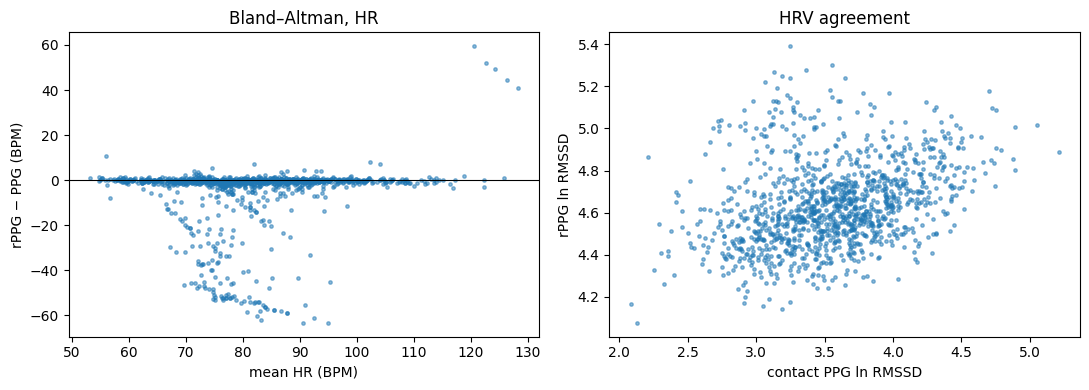

In [21]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

def agree(a, b):
    m = sess[[a, b]].dropna()
    e = m[a] - m[b]
    return dict(n=len(m), mae=e.abs().mean(), bias=e.mean(), within5=(e.abs() < 5).mean(),
                spearman=spearmanr(m[a], m[b])[0])

val = pd.DataFrame({
    'rPPG HR vs PPG HR':  agree('rppg_hr', 'ppg_hr'),
    'rPPG HR vs ECG HR':  agree('rppg_hr', 'ecg_hr'),
    'PPG HR vs ECG HR':   agree('ppg_hr', 'ecg_hr'),
    'rPPG lnRMSSD vs PPG': agree('rppg_ln_rmssd', 'ppg_ln_rmssd'),
    'PPG lnRMSSD vs ECG':  agree('ppg_ln_rmssd', 'ecg_ln_rmssd'),
}).T
print(val.round(3))
for st in ('before', 'after'):
    s = sess[sess.step == st]
    print(st, 'rPPG-PPG HR MAE: %.2f BPM' % (s.rppg_hr - s.ppg_hr).abs().mean())

# Quality flag computed from rPPG only (deployable): good SNR and a stable HR across windows
sess['rppg_good'] = (sess.rppg_snr > 0) & (sess.rppg_hr_consistency > 0.6)
print('good-quality rPPG sessions: %.1f%%' % (100 * sess.rppg_good.mean()))
print('HR MAE in good sessions: %.2f BPM' % (sess[sess.rppg_good].rppg_hr - sess[sess.rppg_good].ppg_hr).abs().mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
m = sess[['rppg_hr', 'ppg_hr']].dropna()
ax[0].scatter((m.rppg_hr + m.ppg_hr) / 2, m.rppg_hr - m.ppg_hr, s=6, alpha=.5)
ax[0].axhline(0, c='k', lw=.8); ax[0].set(xlabel='mean HR (BPM)', ylabel='rPPG − PPG (BPM)', title='Bland–Altman, HR')
m = sess[['rppg_ln_rmssd', 'ppg_ln_rmssd']].dropna()
ax[1].scatter(m.ppg_ln_rmssd, m.rppg_ln_rmssd, s=6, alpha=.5)
ax[1].set(xlabel='contact PPG ln RMSSD', ylabel='rPPG ln RMSSD', title='HRV agreement')
plt.tight_layout(); plt.savefig(RES_DIR / 'rppg_validation.png', dpi=130); plt.show()
val.to_csv(RES_DIR / 'rppg_validation.csv')

## 6. Patient-level table and pre-specified feature sets

- One row per patient. Stress = mean of the two sessions.
- Physiological features get `_rest` (before), `_post` (after) and `_avg` (mean of both) versions, plus `hr_resp` = HR after − HR before.
- Vitals (oracle only) are taken from the resting session.

In [22]:
VITALS = ['upper_ap', 'lower_ap', 'saturation', 'respiratory', 'rigidity', 'pulse']

def build_patient_table(sess, front):
    base = front.sort_values('step').groupby('patient_id')
    P = pd.DataFrame({
        'stress': base.stress.mean(),
        'age': base.age.first(),
        'sex_m': base.sex.first().map({'M': 1, 'F': 0}),
        'bmi': base.bmi.first(),
    })
    rest = front[front.step == 'before'].set_index('patient_id')
    for v in VITALS:
        P[v] = rest[v]
    feat_cols = [c for c in sess.columns if c.split('_')[0] in ('rppg', 'ppg', 'ecg')
                 and not c.endswith('_error') and c != 'rppg_good' and pd.api.types.is_numeric_dtype(sess[c])]
    b = sess[sess.step == 'before'].set_index('patient_id')[feat_cols]
    a = sess[sess.step == 'after'].set_index('patient_id')[feat_cols]
    P = P.join(b.add_suffix('_rest')).join(a.add_suffix('_post'))
    for c in feat_cols:
        P[c + '_avg'] = P[[c + '_rest', c + '_post']].mean(axis=1)
    for src in ('rppg', 'ppg', 'ecg'):
        if f'{src}_hr_rest' in P:
            P[f'{src}_hr_resp'] = P[f'{src}_hr_post'] - P[f'{src}_hr_rest']
    good = sess.groupby('patient_id').rppg_good.mean() if 'rppg_good' in sess else None
    if good is not None:
        P['rppg_good_frac'] = good
    return P.dropna(subset=['stress'])

P = build_patient_table(sess, front)
P.to_csv(FEAT_DIR / 'patient_features.csv')

DEMO = ['age', 'sex_m', 'bmi']
def core(src, kind='rest'):
    cols = [f'{src}_hr_rest', f'{src}_ln_rmssd_{kind}', f'{src}_ln_sdnn_{kind}', f'{src}_ln_hf_{kind}', f'{src}_hr_resp']
    return [c for c in cols if c in P.columns]
QUALITY = ('snr', 'consistency', 'missing', 'dup', 'used_ts', 'fps', 'duration', 'n_beats', 'ok_frac', 'good')
RPPG_FULL = [c for c in P.columns if c.startswith('rppg_') and not c.endswith('_avg')
             and not any(q in c for q in QUALITY)]

FEATURE_SETS = {
    'B1 demographics':              DEMO,
    'B1-oracle demo+vitals':        DEMO + VITALS,
    'B2 rPPG core only':            core('rppg'),
    'B3 demo+rPPG core':            DEMO + core('rppg'),
    'B3 demo+rPPG core (avg)':      DEMO + core('rppg', 'avg'),
    'B3 demo+rPPG full':            DEMO + RPPG_FULL,
    'B2-oracle demo+PPG core':      DEMO + core('ppg'),
    'ECG ceiling demo+ECG core':    DEMO + core('ecg'),
}
for k, v in FEATURE_SETS.items():
    print(f'{k:30s} {len(v):3d} features | complete rows: {P[v].notna().all(axis=1).sum()}')
print('patients:', len(P))

B1 demographics                  3 features | complete rows: 600
B1-oracle demo+vitals            9 features | complete rows: 600
B2 rPPG core only                5 features | complete rows: 598
B3 demo+rPPG core                8 features | complete rows: 598
B3 demo+rPPG core (avg)          8 features | complete rows: 598
B3 demo+rPPG full               40 features | complete rows: 598
B2-oracle demo+PPG core          8 features | complete rows: 600
ECG ceiling demo+ECG core        7 features | complete rows: 580
patients: 600


## 7. Regression: baseline ladder

Every set and model is evaluated on the same 600 patients; missing features are median-imputed inside each training fold.

- **Fixed split** (random_state=43): test MAE, comparable to the published numbers (constant 1.117–1.20).
- **Repeated 5-fold CV** (10×): per-patient absolute error averaged over repeats.
  - Skill = 1 − MAE/MAE_constant.
  - Gain = skill − skill(demographics, Ridge).
  - 95% CIs by patient bootstrap.

In [23]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, QuantileRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin

ALPHAS = np.logspace(-2, 4, 25)
def ridge(alphas=ALPHAS):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), RidgeCV(alphas=alphas))

class DemoResidual(BaseEstimator, RegressorMixin):
    # Demographics Ridge first; then a heavily shrunk Ridge on the remaining features predicts the residual.
    def __init__(self, demo=('age', 'sex_m', 'bmi')):
        self.demo = demo
    def fit(self, X, y):
        X = pd.DataFrame(X)
        self.d_ = [c for c in X.columns if c in self.demo]
        self.r_ = [c for c in X.columns if c not in self.demo]
        self.m1_ = ridge().fit(X[self.d_], y)
        res = y - self.m1_.predict(X[self.d_])
        self.m2_ = ridge(np.logspace(1, 5, 20)).fit(X[self.r_], res) if self.r_ else None
        return self
    def predict(self, X):
        X = pd.DataFrame(X)
        p = self.m1_.predict(X[self.d_])
        return p + self.m2_.predict(X[self.r_]) if self.m2_ is not None else p

MODELS = {
    'Ridge':    lambda: ridge(),
    'MedianQR': lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                      QuantileRegressor(quantile=0.5, alpha=0.05, solver='highs')),
    'RF':       lambda: make_pipeline(SimpleImputer(strategy='median'),
                                      RandomForestRegressor(300, min_samples_leaf=20, max_features=0.5,
                                                            n_jobs=-1, random_state=0)),
    'HGB':      lambda: HistGradientBoostingRegressor(loss='absolute_error', max_depth=3, learning_rate=0.03,
                                                      max_iter=300, min_samples_leaf=30, l2_regularization=1.0,
                                                      random_state=0),
    'Residual': lambda: DemoResidual(),
}

def oof_predictions(X, y, make, n_rep=N_REPEATS, n_folds=N_FOLDS, seed0=100):
    # Out-of-fold predictions, shape (n_rep, n). make=None -> constant (train median).
    preds = np.zeros((n_rep, len(y)))
    for r in range(n_rep):
        for tr, te in KFold(n_folds, shuffle=True, random_state=seed0 + r).split(y):
            if make is None:
                preds[r, te] = np.median(y[tr])
            else:
                m = make().fit(X.iloc[tr], y[tr])
                preds[r, te] = m.predict(X.iloc[te])
    return preds

def boot_skill(e, e0, e_ref=None, n_boot=N_BOOT, seed=1):
    # Skill vs constant (and gain vs a reference) with patient-bootstrap 95% CI.
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(e), (n_boot, len(e)))
    s = 1 - e[idx].sum(1) / e0[idx].sum(1)
    out = dict(skill=1 - e.sum() / e0.sum(), skill_lo=np.percentile(s, 2.5), skill_hi=np.percentile(s, 97.5))
    if e_ref is not None:
        g = s - (1 - e_ref[idx].sum(1) / e0[idx].sum(1))
        out.update(gain=(1 - e.sum() / e0.sum()) - (1 - e_ref.sum() / e0.sum()),
                   gain_lo=np.percentile(g, 2.5), gain_hi=np.percentile(g, 97.5))
    return out

In [24]:
y = P.stress.values
ids = P.index.values

# --- fixed split, as in MCD-rPPG-baselines ---
tr_ids, te_ids = train_test_split(ids, test_size=0.2, random_state=SPLIT_SEED)
tr, te = np.isin(ids, tr_ids), np.isin(ids, te_ids)
fixed = [dict(set='B0 constant', model='median', test_mae=np.mean(np.abs(y[te] - np.median(y[tr]))))]
for sname, cols in FEATURE_SETS.items():
    for mname, make in MODELS.items():
        if mname == 'Residual' and sname == 'B2 rPPG core only':
            continue
        m = make().fit(P.loc[tr, cols], y[tr])
        fixed.append(dict(set=sname, model=mname, test_mae=np.mean(np.abs(y[te] - m.predict(P.loc[te, cols])))))
fixed = pd.DataFrame(fixed)
print(fixed.pivot(index='set', columns='model', values='test_mae').round(3))

# --- repeated CV with bootstrap CIs ---
e0 = np.abs(oof_predictions(None, y, None) - y).mean(0)
e_ref = np.abs(oof_predictions(P[DEMO], y, MODELS['Ridge']) - y).mean(0)
cv = []
OOF = {}
for sname, cols in tqdm(FEATURE_SETS.items()):
    for mname, make in MODELS.items():
        if mname == 'Residual' and sname == 'B2 rPPG core only':
            continue
        pr = oof_predictions(P[cols], y, make)
        OOF[(sname, mname)] = pr
        e = np.abs(pr - y).mean(0)
        cv.append(dict(set=sname, model=mname, mae=e.mean(), **boot_skill(e, e0, e_ref)))
cv = pd.DataFrame(cv)
cv[['skill', 'skill_lo', 'skill_hi', 'gain', 'gain_lo', 'gain_hi']] *= 100
print('constant CV MAE: %.3f' % e0.mean())
print(cv.sort_values('skill', ascending=False).round(2).to_string(index=False))
fixed.to_csv(RES_DIR / 'fixed_split_mae.csv', index=False)
cv.to_csv(RES_DIR / 'cv_skill.csv', index=False)

model                        HGB  MedianQR     RF  Residual  Ridge  median
set                                                                       
B0 constant                  NaN       NaN    NaN       NaN    NaN   1.117
B1 demographics            1.161     1.117  1.173     1.143  1.143     NaN
B1-oracle demo+vitals      1.183     1.117  1.164     1.143  1.144     NaN
B2 rPPG core only          1.142     1.117  1.151       NaN  1.125     NaN
B2-oracle demo+PPG core    1.164     1.117  1.160     1.143  1.146     NaN
B3 demo+rPPG core          1.161     1.117  1.135     1.143  1.144     NaN
B3 demo+rPPG core (avg)    1.154     1.117  1.138     1.143  1.149     NaN
B3 demo+rPPG full          1.203     1.117  1.152     1.143  1.141     NaN
ECG ceiling demo+ECG core  1.137     1.117  1.147     1.143  1.137     NaN


  0%|          | 0/8 [00:00<?, ?it/s]

constant CV MAE: 1.154
                      set    model  mae  skill  skill_lo  skill_hi  gain  gain_lo  gain_hi
          B1 demographics    Ridge 1.15   0.43     -1.82      2.53  0.00     0.00     0.00
          B1 demographics Residual 1.15   0.43     -1.82      2.53  0.00     0.00     0.00
  B2-oracle demo+PPG core Residual 1.15   0.42     -1.82      2.52 -0.00    -0.00    -0.00
    B1-oracle demo+vitals Residual 1.15   0.42     -1.83      2.53 -0.00    -0.01    -0.00
  B3 demo+rPPG core (avg) Residual 1.15   0.41     -1.84      2.50 -0.02    -0.03    -0.01
        B3 demo+rPPG core Residual 1.15   0.39     -1.85      2.49 -0.04    -0.07    -0.00
ECG ceiling demo+ECG core       RF 1.15   0.38     -1.83      2.46 -0.04    -1.15     1.07
ECG ceiling demo+ECG core Residual 1.15   0.36     -1.87      2.46 -0.06    -0.18     0.05
  B2-oracle demo+PPG core       RF 1.15   0.34     -2.12      2.65 -0.08    -1.63     1.50
        B3 demo+rPPG full Residual 1.15   0.27     -1.96      2.37 

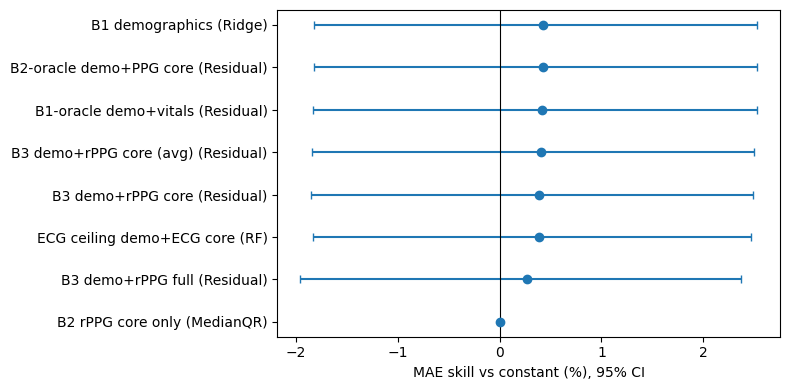

In [25]:
# Best model per feature set: skill vs constant with 95% CI
best = cv.loc[cv.groupby('set').skill.idxmax()].sort_values('skill')
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(best.skill, range(len(best)), xerr=[best.skill - best.skill_lo, best.skill_hi - best.skill],
            fmt='o', capsize=3)
ax.axvline(0, c='k', lw=.8)
ax.set_yticks(range(len(best)), [f'{s} ({m})' for s, m in zip(best.set, best.model)])
ax.set_xlabel('MAE skill vs constant (%), 95% CI')
plt.tight_layout(); plt.savefig(RES_DIR / 'skill_ladder.png', dpi=130); plt.show()

## 8. Sensitivity: good-quality rPPG only

Restricted to patients whose rPPG passed the rPPG-only quality flag in both sessions; demographics are re-evaluated on the same subset. If rPPG helps anywhere, it should show up here.

In [26]:
sub = P[P.get('rppg_good_frac', pd.Series(0, index=P.index)) == 1]
print('patients with good rPPG in both sessions:', len(sub))
if len(sub) >= 100:
    ys = sub.stress.values
    e0s = np.abs(oof_predictions(None, ys, None) - ys).mean(0)
    eds = np.abs(oof_predictions(sub[DEMO], ys, MODELS['Ridge']) - ys).mean(0)
    out = []
    for sname in ('B1 demographics', 'B3 demo+rPPG core', 'B3 demo+rPPG core (avg)', 'B2-oracle demo+PPG core'):
        for mname in ('Ridge', 'Residual'):
            e = np.abs(oof_predictions(sub[FEATURE_SETS[sname]], ys, MODELS[mname]) - ys).mean(0)
            out.append(dict(set=sname, model=mname, **boot_skill(e, e0s, eds)))
    out = pd.DataFrame(out)
    out.iloc[:, 2:] *= 100
    print(out.round(2).to_string(index=False))
    out.to_csv(RES_DIR / 'cv_skill_good_quality.csv', index=False)

patients with good rPPG in both sessions: 95


## 9. Classification

Two targets: high stress (≥ 4.0) and top vs bottom quartile. AUC from repeated stratified 5-fold CV, with patient-bootstrap CIs and the paired ΔAUC vs demographics.

In [27]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score

def logit():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegressionCV(Cs=np.logspace(-3, 2, 12), cv=5, scoring='roc_auc', max_iter=2000))

def oof_proba(X, yb, n_rep=N_REPEATS, seed0=200):
    pr = np.zeros((n_rep, len(yb)))
    for r in range(n_rep):
        for tr, te in StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed0 + r).split(X, yb):
            pr[r, te] = logit().fit(X.iloc[tr], yb[tr]).predict_proba(X.iloc[te])[:, 1]
    return pr.mean(0)

def boot_auc(yb, p, p_ref, n_boot=N_BOOT, seed=2):
    rng = np.random.default_rng(seed)
    a, d = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(yb), len(yb))
        if yb[i].min() == yb[i].max():
            continue
        a.append(roc_auc_score(yb[i], p[i]))
        d.append(a[-1] - roc_auc_score(yb[i], p_ref[i]))
    return dict(auc=roc_auc_score(yb, p), auc_lo=np.percentile(a, 2.5), auc_hi=np.percentile(a, 97.5),
                d_auc=roc_auc_score(yb, p) - roc_auc_score(yb, p_ref),
                d_lo=np.percentile(d, 2.5), d_hi=np.percentile(d, 97.5))

q1, q3 = P.stress.quantile([.25, .75])
TASKS = {
    'high stress (>=4.0)': (P.index, (P.stress >= 4.0).astype(int).values),
    'top vs bottom quartile': (P.index[(P.stress <= q1) | (P.stress >= q3)],
                               (P.stress[(P.stress <= q1) | (P.stress >= q3)] >= q3).astype(int).values),
}
CLF_SETS = ['B1 demographics', 'B1-oracle demo+vitals', 'B3 demo+rPPG core', 'B3 demo+rPPG core (avg)',
            'B2-oracle demo+PPG core', 'ECG ceiling demo+ECG core']
clf = []
for tname, (idx, yb) in TASKS.items():
    print(tname, '| n =', len(yb), '| positive = %.0f%%' % (100 * yb.mean()))
    p_ref = oof_proba(P.loc[idx, DEMO], yb)
    for sname in CLF_SETS:
        p = p_ref if sname == 'B1 demographics' else oof_proba(P.loc[idx, FEATURE_SETS[sname]], yb)
        clf.append(dict(task=tname, set=sname, **boot_auc(yb, p, p_ref)))
clf = pd.DataFrame(clf)
print(clf.round(3).to_string(index=False))
clf.to_csv(RES_DIR / 'classification_auc.csv', index=False)

high stress (>=4.0) | n = 600 | positive = 34%
top vs bottom quartile | n = 422 | positive = 49%
                  task                       set   auc  auc_lo  auc_hi  d_auc   d_lo   d_hi
   high stress (>=4.0)           B1 demographics 0.602   0.557   0.649  0.000  0.000  0.000
   high stress (>=4.0)     B1-oracle demo+vitals 0.581   0.535   0.628 -0.021 -0.060  0.018
   high stress (>=4.0)         B3 demo+rPPG core 0.558   0.511   0.604 -0.044 -0.067 -0.021
   high stress (>=4.0)   B3 demo+rPPG core (avg) 0.587   0.538   0.635 -0.016 -0.043  0.011
   high stress (>=4.0)   B2-oracle demo+PPG core 0.574   0.527   0.620 -0.028 -0.057  0.001
   high stress (>=4.0) ECG ceiling demo+ECG core 0.589   0.542   0.634 -0.013 -0.040  0.011
top vs bottom quartile           B1 demographics 0.653   0.598   0.706  0.000  0.000  0.000
top vs bottom quartile     B1-oracle demo+vitals 0.621   0.568   0.676 -0.031 -0.062 -0.002
top vs bottom quartile         B3 demo+rPPG core 0.622   0.569   0.677 -0.0

## 10. Partial correlations and power

- Partial Spearman ρ of each core feature with stress, adjusting for age, sex and BMI. Shown with a 95% CI and Benjamini–Hochberg q-values.
- Patients needed to detect the observed effect (80% power, α = 0.05), and the MAE skill that effect size could at most give.

In [28]:
from scipy.stats import rankdata, norm
from sklearn.linear_model import LinearRegression

def partial_spearman(df, x, y='stress', cov=DEMO):
    d = df[[x, y] + cov].dropna()
    R = d.apply(rankdata)
    Z = R[cov].values
    rx = R[x] - LinearRegression().fit(Z, R[x]).predict(Z)
    ry = R[y] - LinearRegression().fit(Z, R[y]).predict(Z)
    rho = np.corrcoef(rx, ry)[0, 1]
    n, k = len(d), len(cov)
    se = 1 / np.sqrt(max(n - k - 3, 1))
    z = np.arctanh(rho)
    p = 2 * (1 - norm.cdf(abs(z) / se))
    return dict(feature=x, n=n, rho=rho, lo=np.tanh(z - 1.96 * se), hi=np.tanh(z + 1.96 * se), p=p)

def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = p[o] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q, 1); return out

feats = sorted(set(core('rppg') + core('rppg', 'avg') + core('ppg') + core('ecg')))
pc = pd.DataFrame([partial_spearman(P, f) for f in feats])
pc['q'] = bh(pc.p)
print(pc.round(3).to_string(index=False))
pc.to_csv(RES_DIR / 'partial_correlations.csv', index=False)

def n_needed(rho, power=0.8, alpha=0.05):
    return int(np.ceil(((norm.ppf(1 - alpha / 2) + norm.ppf(power)) / np.arctanh(abs(rho))) ** 2 + 3 + len(DEMO)))

for label, rho in (('largest observed |rho|', pc.rho.abs().max()), ('upper CI of largest', pc.loc[pc.rho.abs().idxmax(), ['lo', 'hi']].abs().max())):
    print(f'{label}: {rho:.3f} -> n for 80% power ≈ {n_needed(rho)}; '
          f'max MAE skill gain ≈ {100 * (1 - np.sqrt(1 - rho ** 2)):.2f}%')

           feature   n    rho     lo    hi     p    q
       ecg_hr_resp 580  0.050 -0.032 0.131 0.230 0.94
       ecg_hr_rest 588 -0.027 -0.108 0.054 0.515 0.94
 ecg_ln_rmssd_rest 588  0.008 -0.073 0.089 0.842 0.94
  ecg_ln_sdnn_rest 588  0.005 -0.076 0.086 0.898 0.94
       ppg_hr_resp 600  0.021 -0.060 0.101 0.614 0.94
       ppg_hr_rest 600  0.003 -0.077 0.083 0.937 0.94
    ppg_ln_hf_rest 600 -0.017 -0.097 0.063 0.680 0.94
 ppg_ln_rmssd_rest 600 -0.032 -0.112 0.048 0.430 0.94
  ppg_ln_sdnn_rest 600 -0.027 -0.107 0.053 0.504 0.94
      rppg_hr_resp 599  0.023 -0.057 0.103 0.570 0.94
      rppg_hr_rest 600 -0.003 -0.083 0.077 0.940 0.94
    rppg_ln_hf_avg 599  0.007 -0.073 0.088 0.859 0.94
   rppg_ln_hf_rest 599  0.053 -0.028 0.133 0.198 0.94
 rppg_ln_rmssd_avg 600 -0.007 -0.087 0.074 0.869 0.94
rppg_ln_rmssd_rest 600  0.014 -0.067 0.094 0.742 0.94
  rppg_ln_sdnn_avg 600 -0.016 -0.096 0.064 0.693 0.94
 rppg_ln_sdnn_rest 600  0.023 -0.058 0.103 0.581 0.94
largest observed |rho|: 0.05

## 11. Summary for the weekly report

In [29]:
def row(s, m='Ridge'):
    r = cv[(cv.set == s) & (cv.model == m)].iloc[0]
    return f"{r.skill:+.2f}% [{r.skill_lo:+.2f}, {r.skill_hi:+.2f}]; gain vs demo {r.gain:+.2f}% [{r.gain_lo:+.2f}, {r.gain_hi:+.2f}]"

print(f"Patients: {len(P)} | constant CV MAE {e0.mean():.3f} | fixed-split constant MAE {fixed.iloc[0].test_mae:.3f}")
print('rPPG HR MAE vs contact PPG: %.2f BPM' % val.loc['rPPG HR vs PPG HR', 'mae'])
for s in FEATURE_SETS:
    print(f'{s:30s} Ridge: {row(s)}')
for s in ('B3 demo+rPPG core', 'B2-oracle demo+PPG core', 'ECG ceiling demo+ECG core'):
    print(f'{s:30s} Residual: {row(s, "Residual")}')
print()
print('Interpretation guide:')
print('* rPPG adds skill only if the gain CI of a "demo+rPPG" row excludes 0.')
print('* If the PPG / ECG oracle rows also show no gain, a better rPPG cannot help: the label is not predictable from pulse/HRV.')
print('* If oracle > demo but rPPG = demo, the bottleneck is rPPG signal quality (see section 5).')

Patients: 600 | constant CV MAE 1.154 | fixed-split constant MAE 1.117
rPPG HR MAE vs contact PPG: 5.53 BPM
B1 demographics                Ridge: +0.43% [-1.82, +2.53]; gain vs demo +0.00% [+0.00, +0.00]
B1-oracle demo+vitals          Ridge: -0.33% [-2.11, +1.37]; gain vs demo -0.76% [-1.37, -0.12]
B2 rPPG core only              Ridge: -0.90% [-1.21, -0.62]; gain vs demo -1.33% [-3.35, +0.71]
B3 demo+rPPG core              Ridge: -0.26% [-2.11, +1.45]; gain vs demo -0.68% [-1.23, -0.13]
B3 demo+rPPG core (avg)        Ridge: -0.25% [-2.16, +1.52]; gain vs demo -0.68% [-1.12, -0.22]
B3 demo+rPPG full              Ridge: -0.59% [-2.41, +1.12]; gain vs demo -1.02% [-2.13, +0.21]
B2-oracle demo+PPG core        Ridge: -0.11% [-2.02, +1.66]; gain vs demo -0.53% [-0.93, -0.11]
ECG ceiling demo+ECG core      Ridge: +0.12% [-1.94, +2.06]; gain vs demo -0.30% [-0.86, +0.26]
B3 demo+rPPG core              Residual: +0.39% [-1.85, +2.49]; gain vs demo -0.04% [-0.07, -0.00]
B2-oracle demo+PPG core  

## 12. Within-person (person-normalised) features: point 3 adapted to MCD only

MCD has no stress task, and PSM-25 is a trait label (0.7% of patients change score between sessions), so rest-vs-stress classification isn't possible here. The closest within-person design MCD allows treats the **15-squat exercise as a standard challenge** and describes each person **relative to their own rest**. That removes between-person baseline differences (fitness, age, skin, camera) that dominate absolute HR and HRV.

Features, from rPPG; the same features from contact PPG serve as the ceiling:
- **Reactivity:** ΔHR (after − rest, from a 15 s windowed HR course), relative ΔHR, Δln RMSSD, Δln SDNN, Δln HF.
- **Recovery** during the after session:
  - HR slope (BPM/min, Theil–Sen).
  - Recovery fraction = (HR in the first 30 s − HR in the last 60 s) / (HR in the first 30 s − rest HR).
- **Rest HR stability:** coefficient of variation of the windowed HR at rest.

The target is still PSM-25. Evaluation is unchanged and patient-level (leave-subjects-out): the fixed split `random_state=43`, repeated 5-fold CV with patient-bootstrap CIs, and partial Spearman correlations.

**Runtime:**
- 12.1 builds a 30 Hz signal cache (rPPG + contact PPG, 1,200 sessions) once, in about 5–15 min, saved to `features/signals_30hz.npz`. Sections 12 and 13 reuse it.
- The rest of section 12 takes about 5–10 min.

**After a restart**, run these in order:
1. Sections 0–2.
2. The first cell of section 3.
3. The first two cells of section 4.
4. Cell 12.0.
5. Section 6.
6. The first cell of section 7.
7. Optionally, the first cell of section 9 (for AUCs) and the first cell of section 10 (for partial correlations).

In [30]:
# 12.0 Resume helper: only needed after a restart (loads section-4 results instead of recomputing them).
if 'sess' not in globals():
    sess = pd.read_csv(FEAT_DIR / 'session_features.csv')
    sess['rppg_good'] = (sess.rppg_snr > 0) & (sess.rppg_hr_consistency > 0.6)
    print('Loaded session features', sess.shape, '-> now run section 6 and the first cell of section 7, then continue here.')
else:
    print('Session features already in memory:', sess.shape)

Session features already in memory: (1200, 67)


In [31]:
# 12.1 30 Hz pulse-signal cache: rPPG (same pipeline as section 4) and contact PPG
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import resample_poly, medfilt
from scipy.stats import theilslopes, spearmanr
from sklearn.model_selection import train_test_split, KFold

def pos_fast(rgb, fs, win=1.6):
    # Vectorised POS: same output as pos() in section 4, much faster.
    N, l = len(rgb), int(round(win * fs))
    W = sliding_window_view(rgb, l, axis=0)                  # (N-l+1, 3, l)
    mu = W.mean(axis=2, keepdims=True); mu[mu == 0] = 1e-9
    C = W / mu
    S0 = C[:, 1] - C[:, 2]
    S1 = -2 * C[:, 0] + C[:, 1] + C[:, 2]
    sd1 = S1.std(axis=1, keepdims=True)
    h = S0 + (S0.std(axis=1, keepdims=True) / np.where(sd1 > 0, sd1, np.inf)) * S1
    h -= h.mean(axis=1, keepdims=True)
    H = np.zeros(N)
    for j in range(l):                                       # overlap-add
        H[j:j + len(h)] += h[:, j]
    return H

def session_time_axis(N, ts, fps_hdr):
    # Same rule as section 4 (with the meta-fps fix): never trust the header fps if meta exists.
    if len(ts) >= 100 and abs(len(ts) - N) <= 5:
        t = np.asarray(ts[:N], float)
        if len(t) < N:
            t = np.concatenate([t, t[-1] + np.arange(1, N - len(t) + 1) * np.median(np.diff(t))])
        return t
    if len(ts) >= 100:
        return np.arange(N) / ((len(ts) - 1) / (ts[-1] - ts[0]))
    return np.arange(N) / (fps_hdr if 5 < fps_hdr < 121 else 30.0)

def rppg_signal(npz_path, meta_path=None):
    # SNR-weighted POS pulse signal at FS_RPPG, band-passed 0.7-3.5 Hz (as in rppg_features).
    z = np.load(npz_path)
    rgb = z['traces'].astype(float)
    dup = z['dup'].astype(bool)
    rgb[dup] = np.nan
    ts = None
    if meta_path is not None and Path(meta_path).exists():
        try:
            ts = parse_meta_timestamps(meta_path)
        except Exception:
            ts = None
    t = session_time_axis(len(rgb), np.array([]) if ts is None else ts, float(z['fps_container']))
    tu = np.arange(t[0], t[-1], 1 / FS_RPPG)
    sigs, snrs = [], []
    for k in range(rgb.shape[1]):
        c = interp_nans(rgb[:, k, :])
        if c is None:
            continue
        cu = np.column_stack([np.interp(tu, t, c[:, j]) for j in range(3)])
        s = bandpass(pos_fast(cu, FS_RPPG), FS_RPPG, *HR_BAND)
        hr_k, f, Pw = hr_harmonic(s, FS_RPPG)
        snr_k = snr_db(f, Pw, hr_k / 60)
        sigs.append(s / (np.std(s) + 1e-12))
        snrs.append(snr_k if np.isfinite(snr_k) else -20)
    if not sigs:
        return None
    w = 10 ** (np.array(snrs) / 10)
    comb = np.sum([wi * si for wi, si in zip(w, sigs)], axis=0) / w.sum()
    return (comb / (comb.std() + 1e-12)).astype(np.float32)

def ppg_signal_30(path):
    # Contact PPG (100 Hz) band-passed like the rPPG and resampled to 30 Hz.
    x = load_pw(path)
    if len(x) < 30 * 100:
        return None
    y = resample_poly(bandpass(detrend(x), 100.0, *HR_BAND), 3, 10)
    return (y / (y.std() + 1e-12)).astype(np.float32)

assert FS_RPPG == 30.0, 'cache assumes 30 Hz'
SIG_CACHE = FEAT_DIR / 'signals_30hz.npz'
if SIG_CACHE.exists():
    with np.load(SIG_CACHE) as zc:
        SIG = {k: zc[k] for k in zc.files}
    print('loaded signal cache:', len(SIG), 'signals')
else:
    SIG = {}
    for r in tqdm(front.to_dict('records')):
        key = f"{r['patient_id']}_{r['step']}"
        try:
            if trace_path(r).exists():
                s = rppg_signal(trace_path(r), DATA_ROOT / r['meta'])
                if s is not None:
                    SIG['rppg_' + key] = s
            if (DATA_ROOT / r['ppg']).exists():
                s = ppg_signal_30(DATA_ROOT / r['ppg'])
                if s is not None:
                    SIG['ppg_' + key] = s
        except Exception as e:
            print(key, repr(e)[:120])
    np.savez_compressed(SIG_CACHE, **SIG)
print('rPPG signals:', sum(k.startswith('rppg_') for k in SIG), '| PPG signals:', sum(k.startswith('ppg_') for k in SIG))

# sanity check: HR from the cached signal should match section 4's rppg_hr
chk = sess.sample(min(40, len(sess)), random_state=0)
d = [hr_harmonic(SIG[f'rppg_{r.patient_id}_{r.step}'], FS_RPPG)[0] - r.rppg_hr
     for r in chk.itertuples() if f'rppg_{r.patient_id}_{r.step}' in SIG and np.isfinite(r.rppg_hr)]
print(f'cache vs section-4 rPPG HR: median |diff| = {np.median(np.abs(d)):.2f} BPM (should be ~0)')

loaded signal cache: 2398 signals
rPPG signals: 1199 | PPG signals: 1199
cache vs section-4 rPPG HR: median |diff| = 0.00 BPM (should be ~0)


In [32]:
# 12.2 Within-person features (each person relative to their own rest)
def hr_course(x, fs, win=15, step=5):
    # Windowed HR (BPM) with a 3-point median filter; returns (window centres in s, HR).
    n, s = int(win * fs), int(step * fs)
    if x is None or len(x) < n:
        return np.array([]), np.array([])
    t = np.array([(i + n / 2) / fs for i in range(0, len(x) - n + 1, s)])
    h = np.array([hr_harmonic(x[i:i + n], fs)[0] for i in range(0, len(x) - n + 1, s)])
    return t, (medfilt(h, 3) if len(h) >= 3 else h)

def within_person(src):
    rows = {}
    for pid in P.index:
        ta, ha = hr_course(SIG.get(f'{src}_{pid}_before'), FS_RPPG)
        tb, hb = hr_course(SIG.get(f'{src}_{pid}_after'), FS_RPPG)
        if len(ha) < 3 or len(hb) < 6:
            continue
        rest, post = np.median(ha), np.median(hb)
        early = np.median(hb[tb <= 22.5])                    # windows within the first 30 s
        late = np.median(hb[tb >= tb.max() - 52.5])          # windows within the last 60 s
        rec = (early - late) / (early - rest) if abs(early - rest) > 3 else np.nan
        rows[pid] = {f'{src}_w_dhr': post - rest,
                     f'{src}_w_rel_dhr': (post - rest) / rest,
                     f'{src}_w_rec_slope': theilslopes(hb, tb / 60)[0],
                     f'{src}_w_rec_frac': float(np.clip(rec, -1, 2)) if np.isfinite(rec) else np.nan,
                     f'{src}_w_rest_hrcv': np.std(ha) / rest}
    W = pd.DataFrame.from_dict(rows, orient='index')
    for k in ('ln_rmssd', 'ln_sdnn', 'ln_hf'):
        a_, b_ = f'{src}_{k}_rest', f'{src}_{k}_post'
        if a_ in P.columns and b_ in P.columns:
            W[f'{src}_w_d{k}'] = (P[b_] - P[a_]).reindex(W.index)
    return W

W_r = within_person('rppg')
W_p = within_person('ppg')
PW = P.join(W_r).join(W_p)
WR, WP = list(W_r.columns), list(W_p.columns)
PW[WR + WP].to_csv(FEAT_DIR / 'within_person_features.csv')
print('patients with rPPG within-person features:', len(W_r), '| contact PPG:', len(W_p))

# How well does rPPG reproduce the contact-PPG within-person features?
agree_w = pd.DataFrame([dict(feature=c.replace('rppg_', ''),
                             spearman=spearmanr(PW[c], PW[c.replace('rppg_', 'ppg_')], nan_policy='omit')[0],
                             rppg_median=PW[c].median(), ppg_median=PW[c.replace('rppg_', 'ppg_')].median())
                        for c in WR if c.replace('rppg_', 'ppg_') in PW.columns])
print(agree_w.round(3).to_string(index=False))

patients with rPPG within-person features: 599 | contact PPG: 599
    feature  spearman  rppg_median  ppg_median
      w_dhr     0.655        2.637       2.637
  w_rel_dhr     0.661        0.033       0.032
w_rec_slope     0.651        0.229       0.465
 w_rec_frac     0.543        0.543       0.431
w_rest_hrcv     0.383        0.060       0.039
w_dln_rmssd     0.218       -0.034      -0.084
 w_dln_sdnn     0.345       -0.004      -0.039
   w_dln_hf     0.160       -0.044      -0.324


In [33]:
# 12.3 Stress prediction with within-person features (same evaluation as section 7)
yW = PW.stress.values
idsW = PW.index.values
tr_ids, te_ids = train_test_split(idsW, test_size=0.2, random_state=SPLIT_SEED)   # same split as section 7
trW, teW = np.isin(idsW, tr_ids), np.isin(idsW, te_ids)

W_SETS = {
    'W rPPG within-person only':            WR,
    'W demo + rPPG within-person':          DEMO + WR,
    'W demo + rPPG within + rPPG core':     DEMO + WR + core('rppg'),
    'W demo + PPG within-person (ceiling)': DEMO + WP,
}
W_MODELS = {k: MODELS[k] for k in ('Ridge', 'RF', 'HGB', 'Residual')}

e0W = np.abs(oof_predictions(None, yW, None) - yW).mean(0)
erefW = np.abs(oof_predictions(PW[DEMO], yW, MODELS['Ridge']) - yW).mean(0)
rows = [dict(set='B0 constant', model='median', test_mae=np.mean(np.abs(yW[teW] - np.median(yW[trW]))), cv_mae=e0W.mean())]
for sname, cols in tqdm(W_SETS.items()):
    for mname, make in W_MODELS.items():
        if mname == 'Residual' and not any(c in DEMO for c in cols):
            continue
        m = make().fit(PW.loc[trW, cols], yW[trW])
        test_mae = np.mean(np.abs(yW[teW] - m.predict(PW.loc[teW, cols])))
        e = np.abs(oof_predictions(PW[cols], yW, make) - yW).mean(0)
        bs = boot_skill(e, e0W, erefW)
        rows.append(dict(set=sname, model=mname, test_mae=test_mae, cv_mae=e.mean(),
                         **{k: 100 * v for k, v in bs.items()}))
wres = pd.DataFrame(rows)
print('Fixed split constant MAE: %.3f | CV constant MAE: %.3f' % (rows[0]['test_mae'], rows[0]['cv_mae']))
print(wres.round(3).to_string(index=False))
wres.to_csv(RES_DIR / 'within_person_regression.csv', index=False)

  0%|          | 0/4 [00:00<?, ?it/s]

Fixed split constant MAE: 1.117 | CV constant MAE: 1.154
                                 set    model  test_mae  cv_mae  skill  skill_lo  skill_hi   gain  gain_lo  gain_hi
                         B0 constant   median     1.117   1.154    NaN       NaN       NaN    NaN      NaN      NaN
           W rPPG within-person only    Ridge     1.140   1.167 -1.079    -1.444    -0.729 -1.504   -3.509    0.546
           W rPPG within-person only       RF     1.164   1.193 -3.330    -4.748    -1.928 -3.755   -5.875   -1.555
           W rPPG within-person only      HGB     1.230   1.215 -5.219    -7.655    -2.847 -5.645   -8.420   -2.859
         W demo + rPPG within-person    Ridge     1.153   1.152  0.189    -1.878     2.043 -0.236   -1.154    0.704
         W demo + rPPG within-person       RF     1.148   1.159 -0.370    -2.632     1.791 -0.795   -2.020    0.457
         W demo + rPPG within-person      HGB     1.191   1.185 -2.682    -5.854     0.411 -3.108   -5.200   -1.065
         W demo

In [34]:
# 12.4 Partial correlations (age, sex, BMI removed) and high-stress AUC for the within-person features
pcw = pd.DataFrame([partial_spearman(PW, f) for f in WR + WP])
pcw['q'] = bh(pcw.p)
print(pcw.round(3).to_string(index=False))
pcw.to_csv(RES_DIR / 'within_person_partial_correlations.csv', index=False)

if 'oof_proba' in globals():
    yb = (PW.stress >= 4.0).astype(int).values
    p_ref = oof_proba(PW[DEMO], yb)
    aucw = pd.DataFrame([dict(set=s, **boot_auc(yb, p_ref if s == 'demographics' else oof_proba(PW[c], yb), p_ref))
                         for s, c in (('demographics', DEMO), ('demo + rPPG within', DEMO + WR),
                                      ('demo + PPG within (ceiling)', DEMO + WP))])
    print('\nHigh stress (>= 4.0) AUC')
    print(aucw.round(3).to_string(index=False))
    aucw.to_csv(RES_DIR / 'within_person_auc.csv', index=False)
else:
    print('Run the first cell of section 9 to also get AUCs.')

         feature   n    rho     lo     hi     p     q
      rppg_w_dhr 599  0.007 -0.073  0.087 0.862 0.945
  rppg_w_rel_dhr 599  0.002 -0.078  0.082 0.962 0.962
rppg_w_rec_slope 599  0.006 -0.074  0.086 0.886 0.945
 rppg_w_rec_frac 450 -0.046 -0.138  0.047 0.336 0.672
rppg_w_rest_hrcv 599 -0.034 -0.114  0.046 0.405 0.705
rppg_w_dln_rmssd 599 -0.032 -0.112  0.049 0.441 0.705
 rppg_w_dln_sdnn 599 -0.077 -0.156  0.003 0.060 0.351
   rppg_w_dln_hf 598 -0.074 -0.154  0.006 0.069 0.351
       ppg_w_dhr 599  0.020 -0.061  0.100 0.631 0.839
   ppg_w_rel_dhr 599  0.017 -0.064  0.097 0.682 0.839
 ppg_w_rec_slope 599 -0.019 -0.099  0.062 0.645 0.839
  ppg_w_rec_frac 426 -0.083 -0.177  0.012 0.088 0.351
 ppg_w_rest_hrcv 599 -0.046 -0.126  0.034 0.259 0.593
 ppg_w_dln_rmssd 599 -0.060 -0.140  0.020 0.141 0.375
  ppg_w_dln_sdnn 599 -0.065 -0.144  0.016 0.114 0.365
    ppg_w_dln_hf 599 -0.086 -0.165 -0.005 0.036 0.351

High stress (>= 4.0) AUC
                        set   auc  auc_lo  auc_hi  d_auc

## 13. 1-D CNN on the band-passed rPPG pulse signal (point 5)

Checks whether a learned model finds stress information that the hand-made HR/HRV features miss.
- **Input:** 20 s windows of the cached rPPG pulse signal (0.7–3.5 Hz), z-scored per window. This removes skin-tone and brightness levels, so the network can't use appearance or identity shortcuts. A second channel flags the before/after session.
- **Target:** PSM-25, with L1 loss (MAE). Each patient's prediction is the mean over all windows of both sessions.
- **Splits:** patient-level only, using the fixed split (`random_state=43`) and 5-fold CV. 10% of the training patients are held out for early stopping.
- **Ceiling:** the same CNN on contact PPG resampled to 30 Hz.

**Runtime:**
- GPU (Runtime → Change runtime type → T4): about 5–15 min in total.
- CPU (2 cores): about 1–2 h.
- On CPU, set `RUN_CV = False` to run only the fixed split (about 15–25 min).
- Changing the runtime type restarts the session, so follow the resume steps in section 12. The signal cache is reloaded from Drive.

In [35]:
# 13.1 CNN definition and training helpers
import torch, torch.nn as nn
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WIN = int(20 * FS_RPPG)          # 20 s windows
CNN_EPOCHS, CNN_PATIENCE = 30, 6
WIN_PER_SESSION, BATCH = 8, 128  # random windows per session per epoch
RUN_CV = True                    # set False on CPU to run only the fixed split
RUN_PPG_CEILING = True
print('device:', DEV)

def zwin(x):
    return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-6)

def session_signals(src, pid):
    out = []
    for flag, step in ((0.0, 'before'), (1.0, 'after')):
        s = SIG.get(f'{src}_{pid}_{step}')
        if s is not None and len(s) >= WIN:
            out.append((s, flag))
    return out

def sample_batch(items, rng):
    X = np.empty((len(items), 2, WIN), np.float32)
    yv = np.empty(len(items), np.float32)
    for i, (s, flag, target) in enumerate(items):
        st = rng.integers(0, len(s) - WIN + 1)       # random crop = augmentation
        X[i, 0] = zwin(s[st:st + WIN]); X[i, 1] = flag; yv[i] = target
    return X, yv

def eval_windows(s, flag, stride):
    idx = np.arange(0, len(s) - WIN + 1, stride)
    X = np.empty((len(idx), 2, WIN), np.float32)
    for i, st in enumerate(idx):
        X[i, 0] = zwin(s[st:st + WIN]); X[i, 1] = flag
    return X

class PulseCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o):
            return nn.Sequential(nn.Conv1d(i, o, 7, padding=3), nn.BatchNorm1d(o), nn.ReLU(), nn.MaxPool1d(2))
        self.features = nn.Sequential(blk(2, 16), blk(16, 32), blk(32, 32), blk(32, 64), blk(64, 64))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.features(x).mean(-1)).squeeze(-1)

@torch.no_grad()
def predict_patients(model, src, pids, stride=int(10 * FS_RPPG)):
    model.eval()
    out = {}
    for pid in pids:
        Xs = [eval_windows(s, f, stride) for s, f in session_signals(src, pid)]
        if Xs:
            out[pid] = float(model(torch.from_numpy(np.concatenate(Xs)).to(DEV)).mean().cpu())
    return out

def train_cnn(src, train_pids, y_map, seed=0):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    pids = np.array([p for p in train_pids if session_signals(src, p)])
    rng.shuffle(pids)
    n_val = max(5, int(0.1 * len(pids)))
    val, fit = pids[:n_val], pids[n_val:]
    yt = np.array([y_map[p] for p in fit])
    mu, sd = float(np.median(yt)), float(yt.std() + 1e-6)
    items = [(s, f, (y_map[p] - mu) / sd) for p in fit for s, f in session_signals(src, p)]
    model = PulseCNN().to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    best, best_state, bad, ep = np.inf, None, 0, 0
    for ep in range(1, CNN_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(items) * WIN_PER_SESSION) % len(items)
        for b in range(0, len(order), BATCH):
            chunk = order[b:b + BATCH]
            if len(chunk) < 2:                       # BatchNorm needs > 1 sample
                continue
            X, yb = sample_batch([items[i] for i in chunk], rng)
            loss = nn.functional.l1_loss(model(torch.from_numpy(X).to(DEV)), torch.from_numpy(yb).to(DEV))
            opt.zero_grad(); loss.backward(); opt.step()
        pv = predict_patients(model, src, val)
        mae = np.mean([abs(pv[p] * sd + mu - y_map[p]) for p in pv])
        if mae < best - 1e-4:
            best, bad = mae, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CNN_PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, mu, sd, best, ep

def cnn_predict(src, train_pids, test_pids, y_map, seed=0):
    model, mu, sd, val_mae, ep = train_cnn(src, train_pids, y_map, seed)
    pv = predict_patients(model, src, test_pids)
    return {p: v * sd + mu for p, v in pv.items()}, val_mae, ep

device: cuda


In [36]:
# 13.2 Train and evaluate (patient-level splits only)
y_map = P.stress.to_dict()
pids_all = P.index.values
ypat = P.stress.values
tr_ids, te_ids = train_test_split(pids_all, test_size=0.2, random_state=SPLIT_SEED)
srcs = ['rppg'] + (['ppg'] if RUN_PPG_CEILING else [])
cnn_rows = []

# fixed split (comparable to section 7 and the published 1.117)
for src in srcs:
    t0 = time.time()
    pred, val_mae, ep = cnn_predict(src, tr_ids, te_ids, y_map, seed=0)
    med = np.median([y_map[p] for p in tr_ids])
    yt = np.array([y_map[p] for p in te_ids])
    pt = np.array([pred.get(p, med) for p in te_ids])
    cnn_rows.append(dict(signal=src, split='fixed (rs=43)', mae=np.mean(np.abs(yt - pt)),
                         const_mae=np.mean(np.abs(yt - med)), spearman=spearmanr(pt, yt)[0],
                         pred_sd=pt.std(), epochs=ep, minutes=(time.time() - t0) / 60))
    print(cnn_rows[-1])

# 5-fold patient CV with bootstrap CIs (constant and demographics refit in the same folds)
if RUN_CV:
    oof = {src: np.zeros(len(pids_all)) for src in srcs}
    e0f, edf = np.zeros(len(pids_all)), np.zeros(len(pids_all))
    for k, (a, b) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=100).split(pids_all)):
        med = np.median(ypat[a])
        e0f[b] = np.abs(ypat[b] - med)
        dm = MODELS['Ridge']().fit(P.iloc[a][DEMO], ypat[a])
        edf[b] = np.abs(ypat[b] - dm.predict(P.iloc[b][DEMO]))
        for src in srcs:
            pred, _, _ = cnn_predict(src, pids_all[a], pids_all[b], y_map, seed=k)
            oof[src][b] = [pred.get(p, med) for p in pids_all[b]]
        print(f'fold {k + 1}/{N_FOLDS} done')
    for src in srcs:
        e = np.abs(oof[src] - ypat)
        bs = boot_skill(e, e0f, edf)
        cnn_rows.append(dict(signal=src, split=f'{N_FOLDS}-fold CV', mae=e.mean(), const_mae=e0f.mean(),
                             spearman=spearmanr(oof[src], ypat)[0], pred_sd=oof[src].std(),
                             **{k: 100 * v for k, v in bs.items()}))

cnn_res = pd.DataFrame(cnn_rows)
print(cnn_res.round(3).to_string(index=False))
cnn_res.to_csv(RES_DIR / 'cnn_pulse_results.csv', index=False)

{'signal': 'rppg', 'split': 'fixed (rs=43)', 'mae': np.float64(1.1338597379114006), 'const_mae': np.float64(1.1172499999999999), 'spearman': np.float64(-0.1867119973917149), 'pred_sd': np.float64(0.04858731948182733), 'epochs': 10, 'minutes': 0.27028359174728395}
{'signal': 'ppg', 'split': 'fixed (rs=43)', 'mae': np.float64(1.1321267731102436), 'const_mae': np.float64(1.1172499999999999), 'spearman': np.float64(-0.165270309583331), 'pred_sd': np.float64(0.0407172799340411), 'epochs': 7, 'minutes': 0.09890920718510945}
fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
signal         split   mae  const_mae  spearman  pred_sd  epochs  minutes  skill  skill_lo  skill_hi   gain  gain_lo  gain_hi
  rppg fixed (rs=43) 1.134      1.117    -0.187    0.049    10.0    0.270    NaN       NaN       NaN    NaN      NaN      NaN
   ppg fixed (rs=43) 1.132      1.117    -0.165    0.041     7.0    0.099    NaN       NaN       NaN    NaN      NaN      NaN
  rppg     5-fold CV 1.165  

## 14. Summary: rPPG-only stress estimates on MCD (sections 7, 12, 13)

In [37]:
lines_out = [f"Constant (train median), fixed split: MAE {wres.iloc[0].test_mae:.3f} | CV: {wres.iloc[0].cv_mae:.3f}"]
if 'fixed' in globals():
    f7 = fixed[(fixed.set == 'B2 rPPG core only') & (fixed.model != 'MedianQR')].sort_values('test_mae').iloc[0]
    lines_out.append(f"Sec 7  rPPG core features only ({f7.model}): fixed-split MAE {f7.test_mae:.3f}")
for s in ('W rPPG within-person only', 'W demo + rPPG within-person', 'W demo + PPG within-person (ceiling)'):
    r = wres[wres.set == s].sort_values('cv_mae').iloc[0]          # best model by CV MAE
    g = f"; gain vs demo {r.gain:+.2f}% [{r.gain_lo:+.2f}, {r.gain_hi:+.2f}]"
    lines_out.append(f"Sec 12 {s} ({r.model}): fixed-split MAE {r.test_mae:.3f} | CV skill {r.skill:+.2f}% "
                     f"[{r.skill_lo:+.2f}, {r.skill_hi:+.2f}]{g}")
for r in cnn_res.itertuples():
    extra = f" | skill {r.skill:+.2f}% [{r.skill_lo:+.2f}, {r.skill_hi:+.2f}]" if 'CV' in r.split else ''
    lines_out.append(f"Sec 13 CNN on {r.signal.upper()} pulse, {r.split}: MAE {r.mae:.3f} vs constant {r.const_mae:.3f}"
                     f" | Spearman {r.spearman:+.3f}{extra}")
print('\n'.join(lines_out))
print('\nRead: a method helps only if its CV skill CI (or gain CI) excludes 0. If the contact-PPG ceiling also fails,')
print('no rPPG algorithm or model can succeed on this label.')

Constant (train median), fixed split: MAE 1.117 | CV: 1.154
Sec 7  rPPG core features only (Ridge): fixed-split MAE 1.125
Sec 12 W rPPG within-person only (Ridge): fixed-split MAE 1.140 | CV skill -1.08% [-1.44, -0.73]; gain vs demo -1.50% [-3.51, +0.55]
Sec 12 W demo + rPPG within-person (Residual): fixed-split MAE 1.142 | CV skill +0.30% [-1.93, +2.40]; gain vs demo -0.12% [-0.30, +0.04]
Sec 12 W demo + PPG within-person (ceiling) (Ridge): fixed-split MAE 1.140 | CV skill +0.51% [-1.44, +2.32]; gain vs demo +0.08% [-0.84, +1.02]
Sec 13 CNN on RPPG pulse, fixed (rs=43): MAE 1.134 vs constant 1.117 | Spearman -0.187
Sec 13 CNN on PPG pulse, fixed (rs=43): MAE 1.132 vs constant 1.117 | Spearman -0.165
Sec 13 CNN on RPPG pulse, 5-fold CV: MAE 1.165 vs constant 1.154 | Spearman -0.079 | skill -0.94% [-1.37, -0.54]
Sec 13 CNN on PPG pulse, 5-fold CV: MAE 1.202 vs constant 1.154 | Spearman -0.105 | skill -4.18% [-5.66, -2.73]

Read: a method helps only if its CV skill CI (or gain CI) exclud